In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [2]:
df = pd.DataFrame({
    "Student_ID": range(1001, 1016),
    "Study_Hours": [
        8, 9, 7, 8, 9,
        4, 5, 3, 4, 5,
        1, 2, 3, 2, 1
    ],
    "Attendance": [
        92, 95, 88, 90, 96,
        70, 75, 65, 72, 78,
        45, 50, 55, 48, 40
    ],
    "Previous_GPA": [
        8.8, 9.2, 8.4, 8.7, 9.5,
        7.0, 7.3, 6.5, 7.1, 7.5,
        5.0, 5.5, 6.0, 5.2, 4.8
    ]
})

print(df.head())

   Student_ID  Study_Hours  Attendance  Previous_GPA
0        1001            8          92           8.8
1        1002            9          95           9.2
2        1003            7          88           8.4
3        1004            8          90           8.7
4        1005            9          96           9.5


In [3]:
features = ["Study_Hours", "Attendance", "Previous_GPA"]

X = df[features]

In [4]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [5]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(X_scaled)

print(df[["Student_ID", *features, "Cluster"]])

    Student_ID  Study_Hours  Attendance  Previous_GPA  Cluster
0         1001            8          92           8.8        2
1         1002            9          95           9.2        2
2         1003            7          88           8.4        2
3         1004            8          90           8.7        2
4         1005            9          96           9.5        2
5         1006            4          70           7.0        0
6         1007            5          75           7.3        0
7         1008            3          65           6.5        0
8         1009            4          72           7.1        0
9         1010            5          78           7.5        0
10        1011            1          45           5.0        1
11        1012            2          50           5.5        1
12        1013            3          55           6.0        1
13        1014            2          48           5.2        1
14        1015            1          40           4.8  

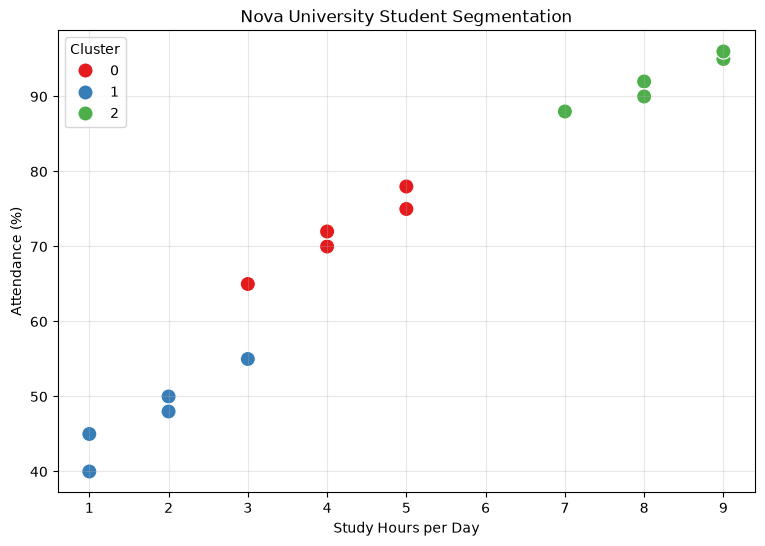

In [6]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Study_Hours",
    y="Attendance",
    hue="Cluster",
    palette="Set1",
    s=120
)

plt.title("Nova University Student Segmentation")
plt.xlabel("Study Hours per Day")
plt.ylabel("Attendance (%)")
plt.grid(alpha=0.3)
plt.show()

In [7]:
centroids = scaler.inverse_transform(kmeans.cluster_centers_)

centroid_df = pd.DataFrame(
    centroids,
    columns=features
)

print(centroid_df.round(2))

   Study_Hours  Attendance  Previous_GPA
0          4.2        72.0          7.08
1          1.8        47.6          5.30
2          8.2        92.2          8.92
